# Binary Thermal Classification — Too Hot vs Not Too Hot

This notebook reproduces the binary population-model experiment for ShadeAdapt.

**Target**
- `0 = Not too hot` → original classes **Not warm / OK + Warm**
- `1 = Too hot` → original class **Too hot**

**Features**
- temperature
- relative humidity
- wind speed
- shortwave solar radiation

The notebook compares Logistic Regression, Random Forest and RBF-SVM, selects the model by **training CV Macro-F1**, and evaluates it on an untouched held-out test set.


In [1]:
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, f1_score,
    precision_score, recall_score, roc_auc_score
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

RANDOM_STATE = 42
TEST_SIZE = 0.20
CV_FOLDS = 5

FEATURES = [
    "temperature_c",
    "relative_humidity",
    "wind_speed_10m_ms",
    "shortwave_radiation_wm2",
]

CLASS_NAMES = ["Not too hot", "Too hot"]
print("Libraries loaded.")


Libraries loaded.


## 1. Load the weather-enriched dataset

In [2]:
def find_data():
    cwd = Path.cwd().resolve()
    candidates = [
        cwd / "thermosurvey_historical_weather_enriched.csv",
        cwd / "data" / "processed" / "thermosurvey_historical_weather_enriched.csv",
        cwd / "ai" / "thermal_model" / "data" / "processed" / "thermosurvey_historical_weather_enriched.csv",
        Path("/mnt/data/thermosurvey_historical_weather_enriched.csv"),
    ]
    for base in [cwd, *cwd.parents]:
        candidates += [
            base / "data" / "processed" / "thermosurvey_historical_weather_enriched.csv",
            base / "ai" / "thermal_model" / "data" / "processed" / "thermosurvey_historical_weather_enriched.csv",
        ]
    for path in candidates:
        if path.exists():
            return path
    raise FileNotFoundError("thermosurvey_historical_weather_enriched.csv not found")

DATA_PATH = find_data()
df = pd.read_csv(DATA_PATH)
print("Using:", DATA_PATH)
print("Shape:", df.shape)


Using: ai/thermal_model\data\processed\thermosurvey_historical_weather_enriched.csv
Shape: (2099, 22)


## 2. Prepare the binary target

Only the same outdoor/semi-outdoor domain used in Experiment 5 is retained (`is_outdoor_or_semi = 1`).


In [3]:
required = ["nr", "city", "thermal_class_code", "is_outdoor_or_semi", *FEATURES]
missing = [c for c in required if c not in df.columns]
if missing:
    raise KeyError(f"Missing columns: {missing}")

data = df[df["is_outdoor_or_semi"] == 1].copy()
data = data.dropna(subset=["city", "thermal_class_code", *FEATURES]).copy()
data["thermal_class_code"] = data["thermal_class_code"].astype(int)

# 0/1 original → Not too hot; 2 original → Too hot
data["too_hot_binary"] = (data["thermal_class_code"] == 2).astype(int)

print("Usable rows:", len(data))
print("\nClass counts:")
print(data["too_hot_binary"].value_counts().sort_index().rename(
    index={0:"Not too hot", 1:"Too hot"}
))
print("\nPercentages:")
print((100 * data["too_hot_binary"].value_counts(normalize=True).sort_index()).round(2))


Usable rows: 689

Class counts:
too_hot_binary
Not too hot    476
Too hot        213
Name: count, dtype: int64

Percentages:
too_hot_binary
0    69.09
1    30.91
Name: proportion, dtype: float64


## 3. Train/test split

In [4]:
data["stratify_key"] = data["city"].astype(str) + "_" + data["too_hot_binary"].astype(str)

train_df, test_df = train_test_split(
    data,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=data["stratify_key"],
)

X_train = train_df[FEATURES].copy()
X_test = test_df[FEATURES].copy()
y_train = train_df["too_hot_binary"].astype(int).copy()
y_test = test_df["too_hot_binary"].astype(int).copy()

print("Train rows:", len(train_df))
print("Test rows:", len(test_df))
print("\nTest city × target:")
print(pd.crosstab(test_df["city"], y_test))


Train rows: 551
Test rows: 138

Test city × target:
too_hot_binary   0   1
city                  
Madrid          29  32
Warsaw          66  11


## 4. Tune candidate models using training data only

Primary model-selection metric: **Macro-F1**


In [5]:
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

models = {
    "Majority Baseline": (
        DummyClassifier(strategy="most_frequent"),
        {}
    ),
    "Logistic Regression": (
        Pipeline([
            ("scale", StandardScaler()),
            ("model", LogisticRegression(
                class_weight="balanced",
                max_iter=3000,
                random_state=RANDOM_STATE
            )),
        ]),
        {"model__C": [0.1, 0.3, 1, 3, 10]}
    ),
    "Random Forest": (
        RandomForestClassifier(
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=-1
        ),
        {
            "n_estimators": [300, 600],
            "max_depth": [5, 8, None],
            "min_samples_leaf": [1, 3, 5],
            "max_features": ["sqrt", None],
        }
    ),
    "RBF-SVM": (
        Pipeline([
            ("scale", StandardScaler()),
            ("model", SVC(
                kernel="rbf",
                probability=True,
                class_weight="balanced",
                random_state=RANDOM_STATE
            )),
        ]),
        {
            "model__C": [0.3, 1, 3, 10],
            "model__gamma": ["scale", 0.01, 0.05, 0.1, 0.3],
        }
    ),
}

searches = {}
rows = []

for name, (estimator, grid) in models.items():
    search = GridSearchCV(
        estimator, grid,
        scoring="f1_macro",
        cv=cv,
        n_jobs=-1,
        refit=True
    )
    search.fit(X_train, y_train)
    searches[name] = search
    rows.append({
        "model": name,
        "cv_macro_f1": search.best_score_,
        "best_params": search.best_params_,
    })

cv_results = pd.DataFrame(rows).sort_values("cv_macro_f1", ascending=False).reset_index(drop=True)
display(cv_results)

selected_name = cv_results.iloc[0]["model"]
print("\nSelected by training CV:", selected_name)


,model,cv_macro_f1,best_params
0,Random Forest,0.769067,"{'max_depth': 8, 'max_features': 'sqrt', 'min_..."
1,RBF-SVM,0.767446,"{'model__C': 10, 'model__gamma': 0.1}"
2,Logistic Regression,0.755567,{'model__C': 1}
3,Majority Baseline,0.408797,{}



Selected by training CV: Random Forest


## 5. Held-out test results

In [6]:
test_rows = []

for name, search in searches.items():
    model = search.best_estimator_
    pred = model.predict(X_test)

    prob_hot = model.predict_proba(X_test)[:,1] if hasattr(model, "predict_proba") else None
    auc = roc_auc_score(y_test, prob_hot) if prob_hot is not None else np.nan

    test_rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "macro_f1": f1_score(y_test, pred, average="macro", zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_test, pred),
        "too_hot_precision": precision_score(y_test, pred, pos_label=1, zero_division=0),
        "too_hot_recall": recall_score(y_test, pred, pos_label=1, zero_division=0),
        "too_hot_f1": f1_score(y_test, pred, pos_label=1, zero_division=0),
        "roc_auc": auc,
    })

test_results = pd.DataFrame(test_rows).sort_values("macro_f1", ascending=False).reset_index(drop=True)
display(test_results)


,model,accuracy,macro_f1,balanced_accuracy,too_hot_precision,too_hot_recall,too_hot_f1,roc_auc
0,RBF-SVM,0.826087,0.811818,0.841860,0.666667,0.883721,0.760000,0.905998
1,Random Forest,0.826087,0.804348,0.816401,0.693878,0.790698,0.739130,0.923133
2,Logistic Regression,0.811594,0.794313,0.818605,0.654545,0.837209,0.734694,0.914565
3,Majority Baseline,0.688406,0.407725,0.500000,0.000000,0.000000,0.000000,0.500000


## 6. Detailed result for the CV-selected model

Selected model: Random Forest

              precision    recall  f1-score   support

 Not too hot      0.899     0.842     0.870        95
     Too hot      0.694     0.791     0.739        43

    accuracy                          0.826       138
   macro avg      0.796     0.816     0.804       138
weighted avg      0.835     0.826     0.829       138

Confusion matrix:
[[80 15]
 [ 9 34]]


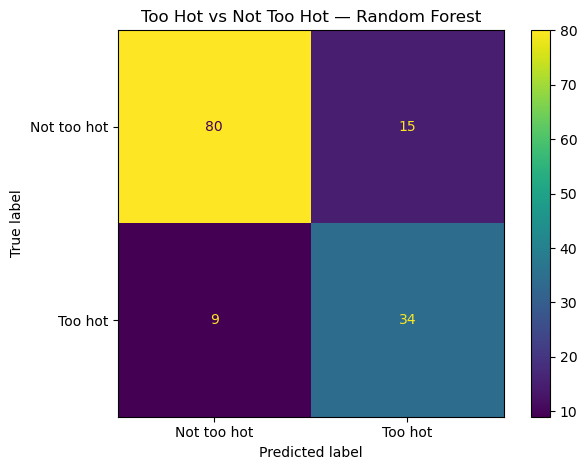

Macro-F1: 0.8043
Balanced accuracy: 0.8164


In [7]:
selected_model = searches[selected_name].best_estimator_
selected_pred = selected_model.predict(X_test)

print("Selected model:", selected_name)
print()
print(classification_report(
    y_test,
    selected_pred,
    target_names=CLASS_NAMES,
    digits=3,
    zero_division=0
))

cm = confusion_matrix(y_test, selected_pred, labels=[0,1])
print("Confusion matrix:")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES
).plot()
plt.title(f"Too Hot vs Not Too Hot — {selected_name}")
plt.tight_layout()
plt.show()

print("Macro-F1:", round(f1_score(y_test, selected_pred, average="macro"), 4))
print("Balanced accuracy:", round(balanced_accuracy_score(y_test, selected_pred), 4))


## 7. Per-city diagnostic

City is **not** an input feature. This section checks whether the selected model behaves differently in Warsaw and Madrid.


In [8]:
city_rows = []

for city in sorted(test_df["city"].unique()):
    mask = test_df["city"].eq(city).to_numpy()
    yt = y_test.to_numpy()[mask]
    yp = np.asarray(selected_pred)[mask]

    city_rows.append({
        "city": city,
        "n": int(mask.sum()),
        "macro_f1": f1_score(yt, yp, average="macro", zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(yt, yp),
        "too_hot_recall": recall_score(yt, yp, pos_label=1, zero_division=0),
        "too_hot_f1": f1_score(yt, yp, pos_label=1, zero_division=0),
    })

city_results = pd.DataFrame(city_rows)
display(city_results)


,city,n,macro_f1,balanced_accuracy,too_hot_recall,too_hot_f1
0,Madrid,61,0.762778,0.76347,0.906250,0.805556
1,Warsaw,77,0.712687,0.69697,0.454545,0.500000


## 8. Too-hot probability output

For ShadeAdapt, `P(Too hot)` can be used by the candidate-time ranking logic together with UV and scheduling constraints.


In [9]:
if hasattr(selected_model, "predict_proba"):
    prob_hot = selected_model.predict_proba(X_test)[:,1]

    examples = test_df[
        ["nr", "city", *FEATURES]
    ].copy()

    examples["actual"] = np.where(y_test.to_numpy() == 1, "Too hot", "Not too hot")
    examples["predicted"] = np.where(selected_pred == 1, "Too hot", "Not too hot")
    examples["probability_too_hot"] = prob_hot

    display(examples.sort_values("probability_too_hot", ascending=False).head(15))
else:
    print("Selected model does not provide probabilities.")


,nr,city,temperature_c,relative_humidity,wind_speed_10m_ms,shortwave_radiation_wm2,actual,predicted,probability_too_hot
450,1538,Madrid,35.6,18.5,3.09,464.0,Too hot,Too hot,0.977810
607,2053,Madrid,34.6,23.7,4.34,719.0,Too hot,Too hot,0.965489
418,1399,Madrid,35.6,22.7,2.92,878.0,Too hot,Too hot,0.952598
449,1536,Madrid,35.6,17.0,3.86,778.0,Too hot,Too hot,0.948623
599,2040,Madrid,34.4,24.5,2.47,26.0,Too hot,Too hot,0.944875
614,2073,Madrid,34.6,21.2,4.43,373.0,Too hot,Too hot,0.933312
438,1518,Madrid,38.2,17.0,2.10,272.0,Too hot,Too hot,0.910316
491,1612,Madrid,35.2,21.0,4.96,444.0,Too hot,Too hot,0.892368
405,1352,Madrid,35.3,22.0,1.61,613.0,Too hot,Too hot,0.883751
489,1609,Madrid,33.4,24.0,3.04,875.0,Too hot,Too hot,0.870513


## 9. Save results and trained model

In [ ]:
# If running inside the repository, save under ai/thermal_model.
cwd = Path.cwd().resolve()
thermal_model_dir = None
for base in [cwd, *cwd.parents]:
    if (base / "data" / "processed").exists() and base.name == "thermal_model":
        thermal_model_dir = base
        break
    candidate = base / "ai" / "thermal_model"
    if (candidate / "data" / "processed").exists():
        thermal_model_dir = candidate
        break

if thermal_model_dir is None:
    thermal_model_dir = cwd

results_dir = thermal_model_dir / "results" / "binary_too_hot"
artifacts_dir = thermal_model_dir / "artifacts" / "binary_too_hot"
results_dir.mkdir(parents=True, exist_ok=True)
artifacts_dir.mkdir(parents=True, exist_ok=True)

cv_results.to_csv(results_dir / "binary_cv_results.csv", index=False)
test_results.to_csv(results_dir / "binary_test_results.csv", index=False)
city_results.to_csv(results_dir / "binary_city_results.csv", index=False)

artifact = {
    "model": selected_model,
    "model_name": selected_name,
    "features": FEATURES,
    "classes": {0: "Not too hot", 1: "Too hot"},
    "target_definition": "Too hot = original thermal_class_code 2; Not too hot = original classes 0 or 1",
    "training_domain_limits": {
        f: {"min": float(train_df[f].min()), "max": float(train_df[f].max())}
        for f in FEATURES
    },
}

model_path = artifacts_dir / "binary_too_hot_model.joblib"
joblib.dump(artifact, model_path)

print("Results:", results_dir)
print("Model:", model_path)


Results: ai/thermal_model\results\binary_too_hot
Model: ai/thermal_model\artifacts\binary_too_hot\binary_too_hot_model.joblib


: 

## Interpretation

This population model predicts **thermal sensation**, not medical heat illness or safety.

If binary classification performs substantially better than the original 3-class model, a practical ShadeAdapt design is:

`weather → P(Too hot) → personal adjustment → combine with UV → rank alternative activity times`

The app can still collect 3-level feedback (`OK / Warm / Too hot`) for personalisation even if the population model itself is binary.
